# Week 4, Lab 9 — Label-free PINNs across the Ghia cases

[Open in Colab](https://colab.research.google.com/github/Ehsan-Roohi/FlowMLLab/blob/main/notebooks/week04/W4_Lab9_Label_Free_Ghia_PINN_Audit.ipynb)

**Prerequisites:** complete Week 4 CFD/POD foundations and [Week 13 Part A: build a small streamfunction PINN](../week13/W13_Rectangular_Cavity_PINN_Research.ipynb) before this research audit. This is an advanced branch; its Week 4 location does not make it a prerequisite for introductory field learning.

This additive lab studies case-specific PINNs at
$Re=100,400,1000,3200,5000,7500,10000$. The admitted matrix has three seeds (7, 23, 61) and both declared collars per Re.
Each model uses four tanh layers of width 64, float64, 2048 fixed points, 2000 Adam
updates followed by 500 L-BFGS outer updates. Completed updates and actual closures
are different counts. Each model solves its own Re; this is not
one network predicting an unseen Re. [Lab 7](W4_Lab7_High_Re_CFD_Ghia.ipynb) supplies
CFD qualification and [Lab 8](W4_Lab8_High_Re_Field_DeepONet.ipynb) supplies a separate
supervised POD-DeepONet comparison. Earlier lessons remain intact.

**Learning goals:** audit exact boundary conditions, distinguish objective loss from
physical/field error, compare matched costs, and inspect weak vortices. Run All reads
retained evidence on CPU. Missing fresh results are reported explicitly; this lesson
alone does not demonstrate new accuracy.

[Campaign protocol](../../docs/CAVITY_PINN_CAMPAIGN_PROTOCOL.md) ·
[CFD evidence](../../results/cavity_highre_ghia/README.md)

**CPU setup:** use the existing checkout, or let the first cell clone the published repository once when none is found. Existing folders and student edits are preserved. Colab already supplies NumPy, pandas, Matplotlib and IPython; a local environment needs those packages. This evidence-only route needs no Torch, TensorFlow or GPU. The initial repository download can take longer than the numerical audit. A missing campaign is reported explicitly; no external result archive is downloaded.

In [1]:
# FLOWMLLAB_COLAB_BOOTSTRAP_V1
# Run All reads retained evidence on CPU; it never starts training or HPC jobs.
# Outside a checkout, obtain the published repository once. Preserve existing work.
from pathlib import Path
import hashlib, json, subprocess, sys
from datetime import datetime
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents, Path('/content/FlowMLLab')]
             if (p/'flowmllab/ghia.py').is_file() and (p/'results').is_dir()), None)
if ROOT is None:
    candidate = Path('/content/FlowMLLab') if Path('/content').is_dir() else Path.cwd()/'FlowMLLab'
    if not candidate.exists():
        subprocess.run(['git','clone','--depth','1',
                        'https://github.com/Ehsan-Roohi/FlowMLLab.git',str(candidate)],check=True)
    if not (candidate/'flowmllab/ghia.py').is_file() or not (candidate/'results').is_dir():
        raise RuntimeError('Use an updated FlowMLLab checkout after saving your student work; '
                           'this cell never overwrites an existing directory or edited notebook.')
    ROOT = candidate
ROOT = ROOT.resolve()
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
print('Evidence checkout:', ROOT)

def verified_file(entry):
    path = (ROOT/entry['path']).resolve()
    if not path.is_relative_to(ROOT.resolve()):
        raise ValueError('Evidence must stay inside the checkout.')
    if hashlib.sha256(path.read_bytes()).hexdigest() != entry['sha256']:
        raise ValueError('SHA256 mismatch: '+entry['path'])
    return path

def stamp(value):
    result = datetime.fromisoformat(value.replace('Z','+00:00'))
    if result.tzinfo is None:
        raise ValueError('Use timezone-aware evidence timestamps.')
    return result

def load_campaign(folder, kind):
    path = ROOT/folder/'evaluation_manifest.json'
    if not path.exists():
        print('Fresh campaign results are not included in this checkout yet.')
        print('Study design and exercises are available; no numerical outcome is fabricated.')
        return {'records': [], 'status':'not_available'}
    manifest = json.loads(path.read_text(encoding='utf-8'))
    assert manifest['schema_version']==1 and manifest['campaign_kind']==kind
    seen=set()
    for row in manifest['records']:
        if manifest.get('path_base')=='manifest_directory':
            for key in ['prediction','reference','comparison_prediction','history','training_manifest','training_contract']:
                if key in row:
                    evidence=(path.parent/row[key]['path']).resolve()
                    if not evidence.is_relative_to(ROOT.resolve()):
                        raise ValueError('Published evidence must remain inside the checkout.')
                    row[key]=dict(row[key],path=evidence.relative_to(ROOT.resolve()).as_posix())
        if 'history' in row: verified_file(row['history'])
        if row['run_id'] in seen:
            raise ValueError('Duplicate run_id; a restart is not another seed.')
        seen.add(row['run_id'])
        for provenance_key in ['training_manifest','training_contract']:
            if provenance_key in row: verified_file(row[provenance_key])
        if row['outcome'] not in ('scored','controlled_pilot_scored'):
            continue
        if not (row['prediction']['sha256']==row['freeze']['prediction_sha256']
                ==row['score']['prediction_sha256']):
            raise ValueError('Scored prediction differs from the frozen prediction.')
        if stamp(row['freeze']['at_utc'])>stamp(row['score']['reference_accessed_at_utc']):
            raise ValueError('Reference access predates recorded prediction freeze.')
        verified_file(row['prediction']); verified_file(row['reference'])
        if 'comparison_prediction' in row:
            if row['comparison_prediction']['source_prediction_sha256']!=row['prediction']['sha256']:
                raise ValueError('Derived comparison does not bind the original frozen prediction.')
            verified_file(row['comparison_prediction'])
        if 'history' in row: verified_file(row['history'])
        if 'ghia_profiles' in row: verified_file(row['ghia_profiles'])
    if manifest.get('path_base')=='manifest_directory':
        for item in manifest.get('figures',[]):
            resolved=(path.parent/item['path']).resolve()
            if not resolved.is_relative_to(ROOT.resolve()):raise ValueError('Figure must stay inside checkout.')
            item['path']=resolved.relative_to(ROOT.resolve()).as_posix()
            verified_file(item)
    print('Campaign status:',manifest['status'])
    return manifest

def show_history(rows):
    rows=[r for r in rows if 'history' in r]
    if not rows:
        print('No verified convergence history for this selection.'); return
    metric_names={r['history']['metric_name'] for r in rows}
    if len(metric_names)!=1: raise ValueError('Do not overlay unlike convergence metrics.')
    for r in rows:
        print(r['run_id'],r['history']['metric_label'],'; independent audit =',r['history']['independent_audit'])
        print('History location:',r['history'].get('loss_location','recorded in protocol'))
        print('Time scope:',r['history'].get('time_scope','recorded in protocol'))
    fig,axes=plt.subplots(1,2,figsize=(10,3.4))
    for r in rows:
        h=pd.read_csv(verified_file(r['history']))
        for ax,column in zip(axes,['objective_evaluations','elapsed_seconds']):
            label=f"{r['method']}, seed {r['seed']}"
            if 'collar' in r: label+=f", epsilon={r['collar']:g}"
            ax.plot(h[column],h['metric_value'],label=label)
            ax.set(xlabel=column.replace('_',' '),ylabel=r['history']['metric_label'])
            ax.set_yscale('symlog',linthresh=1e-12);ax.grid(alpha=.2)
    fig.legend(*axes[0].get_legend_handles_labels(),loc='lower center',
               bbox_to_anchor=(.5,-.16),ncol=2,frameon=False)
    fig.tight_layout();plt.show()

def show_native_profiles(row, heights):
    fields=[]
    for key in [('comparison_prediction' if 'comparison_prediction' in row else 'prediction'),'reference']:
        with np.load(verified_file(row[key]),allow_pickle=False) as f:
            fields.append({k:f[k].copy() for k in f.files})
    pred,ref=fields
    # D5 native exports name physical floor height h; no byte/file rewrite is needed.
    for field in fields:
        if 'y' not in field and 'h' in field: field['y']=field['h']
    for key in ['x','y']:
        if ref[key].ndim!=1 or not np.array_equal(pred[key],ref[key]):
            raise ValueError('Matched physical native coordinates are required.')
        if not np.all(np.diff(ref[key])>0): raise ValueError('Coordinates must increase.')
    variables=[v for v in ['u','v','p','omega'] if v in pred and v in ref]
    shape=(len(ref['y']),len(ref['x']))
    for field in fields:
        for v in variables:
            if field[v].shape!=shape or not np.isfinite(field[v]).all():
                raise ValueError('Invalid field: '+v)
    if 'p' in variables and 'comparison_prediction' not in row:
        def w(c):
            d=np.diff(c);return np.r_[d[0]/2,(d[:-1]+d[1:])/2,d[-1]/2]
        weights=np.outer(w(ref['y']),w(ref['x']))[1:-1,1:-1]
        pred['p']-=np.sum(weights*(pred['p']-ref['p'])[1:-1,1:-1])/weights.sum()
    for height in heights:
        j=int(np.argmin(abs(ref['y']-height)))
        print('Native physical row y/W =',ref['y'][j],'; requested =',height)
        fig,axes=plt.subplots(1,len(variables),figsize=(3.3*len(variables),3.1),squeeze=False)
        for ax,v in zip(axes[0],variables):
            ax.plot(ref['x'],ref[v][j],color='black',label='CFD reference')
            ax.plot(pred['x'],pred[v][j],color='tab:orange',ls='--',label='Frozen PINN')
            ax.set(xlabel='x/W',ylabel=v+' (nondimensional)');ax.grid(alpha=.2)
        fig.legend(*axes[0,0].get_legend_handles_labels(),loc='lower center',
                   bbox_to_anchor=(.5,-.13),ncol=2,frameon=False)
        fig.tight_layout();plt.show()

CAMPAIGN=load_campaign('results/cavity_pinn_campaign','ghia_constant_lid')
display(pd.DataFrame(CAMPAIGN['records']).reindex(columns=['run_id','Re','seed','method','outcome','collar']))

Evidence checkout: D:\ChatGPT Backup\Projects\FlowMLLab\Teaching_Current\repo
Campaign status: scored available frozen runs; campaign and physical acceptance not implied


,run_id,Re,seed,method,outcome,collar
0,re100_s7_eps0.01_2c826f7633,100,7,"Adam-to-L-BFGS, fixed collocation",scored,0.01
1,re100_s7_eps0.02_62d1c7ccc2,100,7,"Adam-to-L-BFGS, fixed collocation",scored,0.02
2,re100_s23_eps0.01_74e2354a29,100,23,"Adam-to-L-BFGS, fixed collocation",scored,0.01
3,re100_s23_eps0.02_83805bfe22,100,23,"Adam-to-L-BFGS, fixed collocation",scored,0.02
4,re100_s61_eps0.01_de2509420a,100,61,"Adam-to-L-BFGS, fixed collocation",scored,0.01
5,re100_s61_eps0.02_078ff8b31a,100,61,"Adam-to-L-BFGS, fixed collocation",scored,0.02
6,re400_s7_eps0.01_62c49bac9c,400,7,"Adam-to-L-BFGS, fixed collocation",scored,0.01
7,re400_s7_eps0.02_e33f778ac0,400,7,"Adam-to-L-BFGS, fixed collocation",scored,0.02
8,re400_s23_eps0.01_fcbe10e56c,400,23,"Adam-to-L-BFGS, fixed collocation",scored,0.01
9,re400_s23_eps0.02_69abc57ce6,400,23,"Adam-to-L-BFGS, fixed collocation",scored,0.02


## 1. Equations and the exact lid

Let $x=X/W,y=Y/W\in[0,1]$, $u,v$ be velocities divided by lid speed $U$, and
$p=P/(\rho U^2)$. Width $W$, density $\rho$ and kinematic viscosity $\nu$ define
$Re=UW/\nu$. Subscripts denote derivatives in these physical nondimensional coordinates.

$$r_c=u_x+v_y=0,$$
$$r_x=uu_x+vu_y+p_x-Re^{-1}(u_{xx}+u_{yy})=0,$$
$$r_y=uv_x+vv_y+p_y-Re^{-1}(v_{xx}+v_{yy})=0.$$

The open top wall has $(u,v)=(1,0)$; the other open walls have $(0,0)$.
The incompatible top-corner limits are singular. A smoothed Gaussian/polynomial
lid changes the benchmark. A streamfunction $u=\psi_y,v=-\psi_x$ enforces continuity
by mixed-partial symmetry; signed vorticity is $\omega=v_x-u_y=-\nabla^2\psi$.
Manufactured residual, pressure-sign and random-network wall-derivative tests must
verify these identities before a production run.

## 2. The corner treatment is an explicit approximation

The reviewed pilot uses leading Stokes corner velocity **and pressure** subtraction;
the precise formula and derivative tests are in the protocol. A generic rational
lifting imposed an uncorrectable leading singular defect and was rejected before
training. Even Stokes subtraction can leave $O(1/r)$ residuals after global blending
and nonlinear terms, where $r$ is distance to a top corner.

The declared collocation collar is $\varepsilon=0.02W$, with a paired $0.01W$
sensitivity experiment. The open-wall lid remains constant. Original unscaled
residuals must also be audited in excluded shells. A low loss outside the collar
does not establish accuracy inside it or full-domain strong-residual convergence.
Report collar norm, minimum sampled distance and sample counts; random avoidance
of a corner is not a documented regularization.

## 3. Residual-guided sampling without changing the objective

The implemented Ghia baseline uses fixed uniform collocation; adaptive sampling
is a future controlled extension. The following estimator exercise does not imply
that an adaptive cavity model has been trained.

For $N$ candidate points, let $f_i=r_x(\mathbf x_i)^2+r_y(\mathbf x_i)^2$ and
$J_N=N^{-1}\sum_i f_i$. For $m$ draws with replacement, $P(I_j=i)=q_i>0$,

$$\widehat J_N=\frac1m\sum_{j=1}^m\frac{f_{I_j}}{Nq_{I_j}}.$$

A uniform proposal component keeps all probabilities positive. Clipping or
self-normalizing these weights changes the estimator. A plain adaptive sample mean
also changes the objective. This small finite-sum check is a mathematical exercise,
not a cavity output.

In [2]:
x=np.linspace(0,1,101)
f=1+20*np.exp(-((x-.85)/.04)**2)
N=len(x);mixture=.2
q=mixture/N+(1-mixture)*f/f.sum()
values={'Uniform objective':f.mean(),'Expected weighted estimate':np.sum(q*f/(N*q)),
        'Expected unweighted adaptive estimate':np.sum(q*f)}
display(pd.Series(values,name='Finite-pool toy calculation'))
assert np.isclose(values['Uniform objective'],values['Expected weighted estimate'],rtol=1e-13)

Uniform objective                        2.403924
Expected weighted estimate               2.403924
Expected unweighted adaptive estimate    8.355353
Name: Finite-pool toy calculation, dtype: float64

## A measured computation lesson: aggregate identical work

The GPU probe changes computational chunk size, while retaining the same initial
network and all 2048 collocation points in each full gradient. It is not a change
in stochastic minibatch size. Five consecutive Adam updates per chunk were timed
on one Quadro RTX 8000; the reported value is the median of the last three.
These are not independent timing replicates. The cost curve is not an accuracy
curve. Initial loss/gradient checks support equivalence at the tested state;
they do not prove every future trajectory or device is bitwise identical.

five consecutive Adam updates per chunk; median of last three; not independent replicates


,chunk_points,median_update_seconds,peak_allocated_MB_decimal,initial_gradient_max_difference
0,256,1.578030,108.201984,0.000000e+00
1,512,0.806116,148.881408,2.220446e-16
2,1024,0.417256,230.240256,2.220446e-16
3,2048,0.207165,392.855040,2.220446e-16


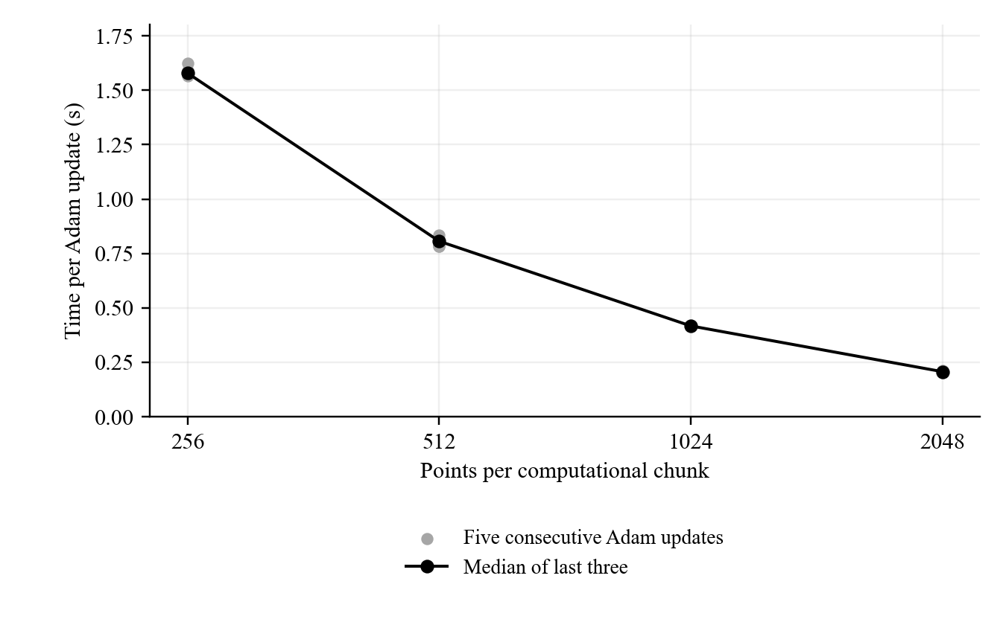

In [3]:
cost_dir=ROOT/'results/cavity_pinn_campaign/cost_study'
if (cost_dir/'manifest.json').exists():
    cost_manifest=json.loads((cost_dir/'manifest.json').read_text())
    cost=json.loads(verified_file(cost_manifest['source_probe']).read_text())
    rows=cost['rows']
    for row in rows:
        assert np.isclose(np.median(row['times_seconds'][-3:]),row['median_last3_seconds'],rtol=1e-13)
    display(pd.DataFrame([{'chunk_points':r['chunk_size'],'median_update_seconds':r['median_last3_seconds'],
                           'peak_allocated_MB_decimal':r['peak_allocated_bytes']/1e6,
                           'initial_gradient_max_difference':r['gradient_max_abs_difference']} for r in rows]))
    from IPython.display import Image
    display(Image(filename=str(verified_file(cost_manifest['figure'])),width=700))
    print(cost_manifest['timing_scope'])
else:
    print('No verified chunk-cost probe is included.')

## Information, work and recovery

| Record | Required control |
| --- | --- |
| Initial parameters, samples, architecture, physics | Identical within each paired seed |
| Endpoint/audit rule | Ghia uses the last fixed-budget endpoint; final audits never select it |
| CFD/Ghia references | Read for scoring only after prediction freezing |
| Quasi-Newton objective | Freeze collocation and weights during every line search |
| Work | Count closures, line-search trials, candidate-pool residual evaluations and elapsed time |
| Seeds | Preserve every predeclared outcome and failure; a restart is not another seed |

Adam supplies moment-scaled first-order steps; L-BFGS uses secant information to
approximate inverse curvature. Staging can help ill-conditioning but cannot repair
wrong boundary conditions or an inadequate representation. Explain a measured gain
using residual-component gradient norms/cosines, accepted steps and physical audits;
the optimizer's name is not evidence. Compare evaluation and time budgets, because
one iteration can contain several expensive closures.

A complete restart contains model, optimizer/history, RNG, exact samples/weights,
stage, counters, frozen-endpoint identity, configuration and source identities. Any separately implemented best-state selection also needs its state saved. Verify
interrupted/uninterrupted agreement through the next accepted update in each stage.
A weight file alone cannot resume the same optimizer trajectory.

re100_s7_eps0.01_2c826f7633 Training momentum RMS outside collar ; independent audit = False
History location: last closure; not a recomputed accepted endpoint
Time scope: optimizer-step time; excludes admission, checkpoint I/O and final reference evaluation
re100_s7_eps0.02_62d1c7ccc2 Training momentum RMS outside collar ; independent audit = False
History location: last closure; not a recomputed accepted endpoint
Time scope: optimizer-step time; excludes admission, checkpoint I/O and final reference evaluation


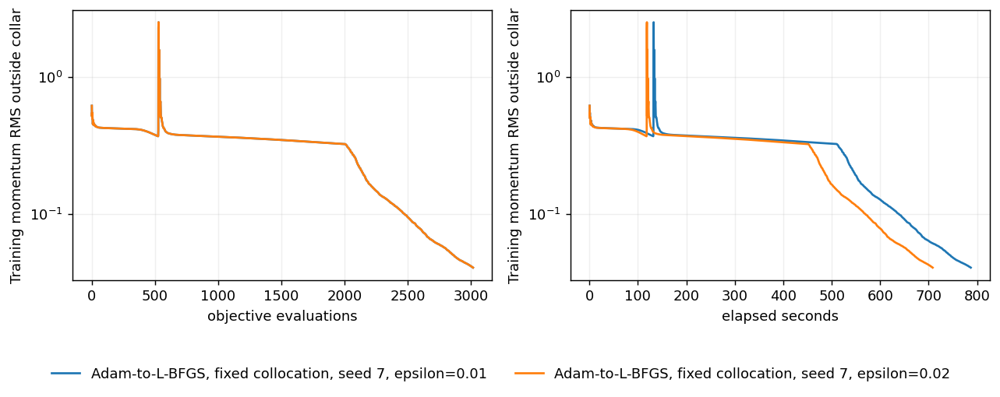

In [4]:
RE=100
SEED=7
selected=[r for r in CAMPAIGN['records'] if r['Re']==RE and r['seed']==SEED]
show_history(selected)

## Physical comparison and error meaning

For a declared region $R$ and physical quadrature weights $w_i$, report reference
velocity RMS $A_R$, absolute vector-error RMS $e_R$, and relative error $E_R=e_R/A_R$:

$$A_R^2=\frac{\sum_{i\in R}w_i(u_i^2+v_i^2)}{\sum_{i\in R}w_i},\qquad
 e_R^2=\frac{\sum_{i\in R}w_i[(\hat u_i-u_i)^2+(\hat v_i-v_i)^2]}{\sum_{i\in R}w_i}.$$

A weak lower vortex can have a very small $A_R$; preserve both absolute and relative
errors. Use one whole-interior pressure gauge and retain signed regional pressure
means/RMS; never refit a separate offset in each region. Signed vorticity and native
profiles reveal behavior that speed magnitude can hide. The cell below shows only
actual matched native rows and explicitly reports their heights. Missing pressure
or vorticity data are not silently reconstructed. Each Re/seed is inspected separately.
For the Ghia native profiles, omega compares PINN automatic derivatives with CFD
transported vorticity. The separate gallery computes the same centered curl from
both stored velocity fields on a common 509-by-509 grid; these are different
diagnostics and neither overwrites the frozen scores.

CFD grid sensitivity and PINN discrepancy are different quantities. The existing
square-cavity 256-to-512 velocity differences are 2.03%, 3.14%, 4.72%, 6.32% at
Re3200/5000/7500/10000; they are sensitivity measures, not exact-error bounds.
A steady root does not demonstrate asymptotic temporal stability.

re100_s7_eps0.01_2c826f7633 Adam-to-L-BFGS, fixed collocation
Native physical row y/W = 0.099609375 ; requested = 0.1
Native physical row y/W = 0.5 ; requested = 0.5
Native physical row y/W = 0.900390625 ; requested = 0.9
re100_s7_eps0.02_62d1c7ccc2 Adam-to-L-BFGS, fixed collocation
Native physical row y/W = 0.099609375 ; requested = 0.1
Native physical row y/W = 0.5 ; requested = 0.5
Native physical row y/W = 0.900390625 ; requested = 0.9


,sample_count,reference_velocity_rms_U,velocity_error_rms_U,velocity_relative_l2,u_error_signed_mean_U,v_error_signed_mean_U,omega_error_rms_U_over_W,omega_error_signed_mean_U_over_W,omega_relative_l2
interior,261121,0.259893,0.008617,0.033157,-0.000014,-3.008975e-06,0.230640,0.000727,0.054031
lower_quarter,65408,0.056617,0.002810,0.049630,-0.001934,-6.488404e-09,0.027507,0.007520,0.082629
upper_quarter,65408,0.426758,0.010359,0.024273,-0.005745,-1.056196e-05,0.435202,-0.017825,0.052721


,corner_shells,interpretation,boundary.top.u_max_abs_error,boundary.top.v_max_abs_error,boundary.bottom.u_max_abs_error,boundary.bottom.v_max_abs_error,boundary.left.u_max_abs_error,boundary.left.v_max_abs_error,boundary.right.u_max_abs_error,boundary.right.v_max_abs_error,outer_uniform.count,outer_uniform.minimum_corner_distance,outer_uniform.rx_rms,outer_uniform.ry_rms,outer_uniform.momentum_rms,outer_uniform.momentum_max,outer_uniform.divergence_rms,outer_uniform.finite
0,"[{'r_min': 0.0001, 'r_max': 0.001, 'count': 25...",Raw unweighted samples; no full-domain integra...,2.220446e-16,0.0,0.0,0.0,0.0,2.220446e-16,0.0,2.220446e-16,2048,0.025911,0.136321,0.103672,0.171263,4.24457,1.224084e-15,True


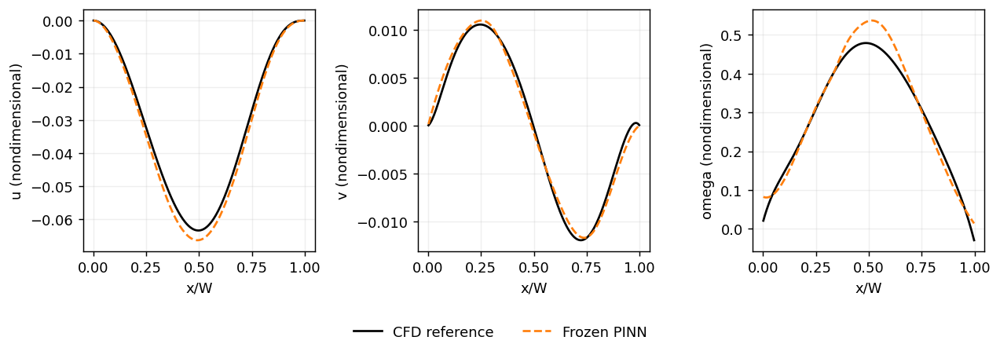

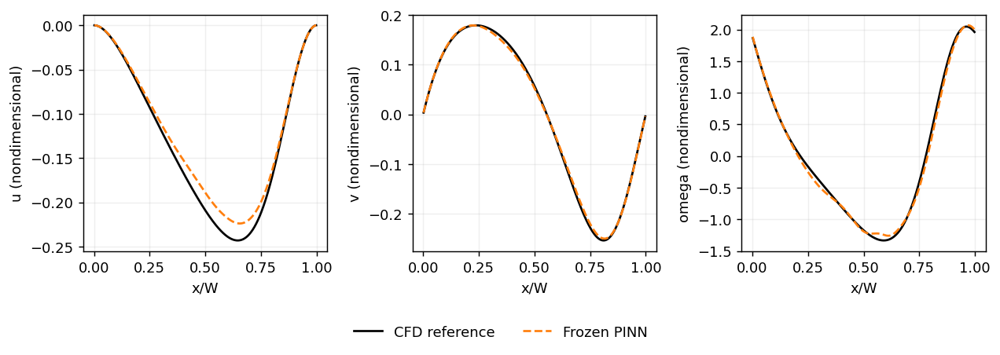

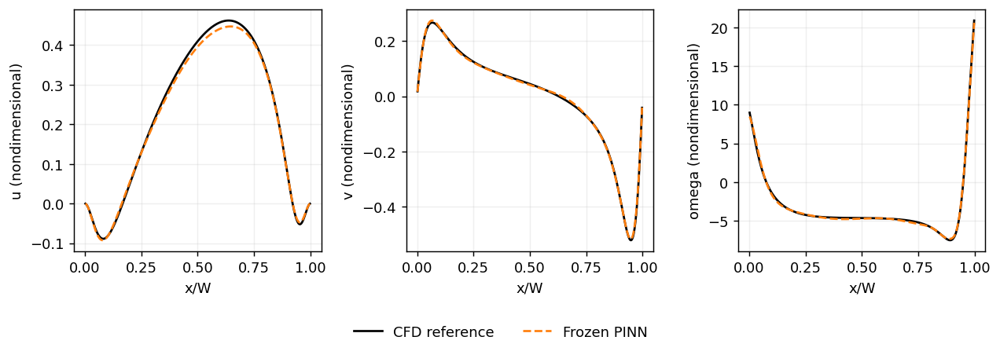

,sample_count,reference_velocity_rms_U,velocity_error_rms_U,velocity_relative_l2,u_error_signed_mean_U,v_error_signed_mean_U,omega_error_rms_U_over_W,omega_error_signed_mean_U_over_W,omega_relative_l2
interior,261121,0.259893,0.008617,0.033157,-0.000014,-3.008975e-06,0.230640,0.000727,0.054031
lower_quarter,65408,0.056617,0.002810,0.049630,-0.001934,-6.488404e-09,0.027507,0.007520,0.082629
upper_quarter,65408,0.426758,0.010359,0.024273,-0.005745,-1.056196e-05,0.435202,-0.017825,0.052721


,corner_shells,interpretation,boundary.top.u_max_abs_error,boundary.top.v_max_abs_error,boundary.bottom.u_max_abs_error,boundary.bottom.v_max_abs_error,boundary.left.u_max_abs_error,boundary.left.v_max_abs_error,boundary.right.u_max_abs_error,boundary.right.v_max_abs_error,outer_uniform.count,outer_uniform.minimum_corner_distance,outer_uniform.rx_rms,outer_uniform.ry_rms,outer_uniform.momentum_rms,outer_uniform.momentum_max,outer_uniform.divergence_rms,outer_uniform.finite
0,"[{'r_min': 0.0001, 'r_max': 0.001, 'count': 25...",Raw unweighted samples; no full-domain integra...,2.220446e-16,0.0,0.0,0.0,0.0,2.220446e-16,0.0,2.220446e-16,2048,0.025911,0.136321,0.103672,0.171263,4.24457,1.224084e-15,True


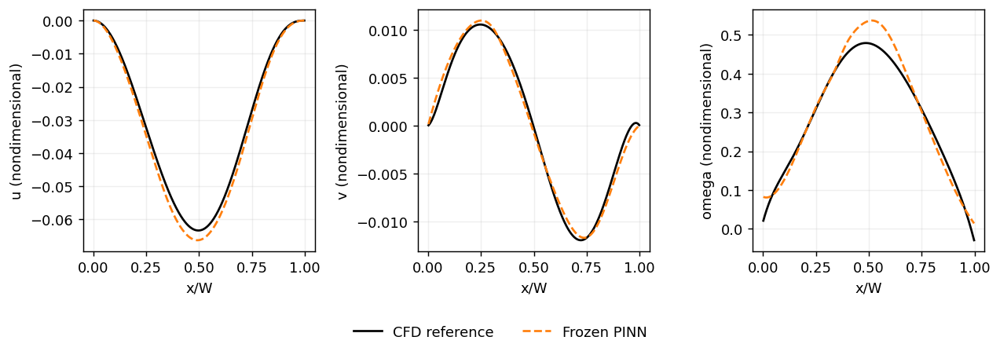

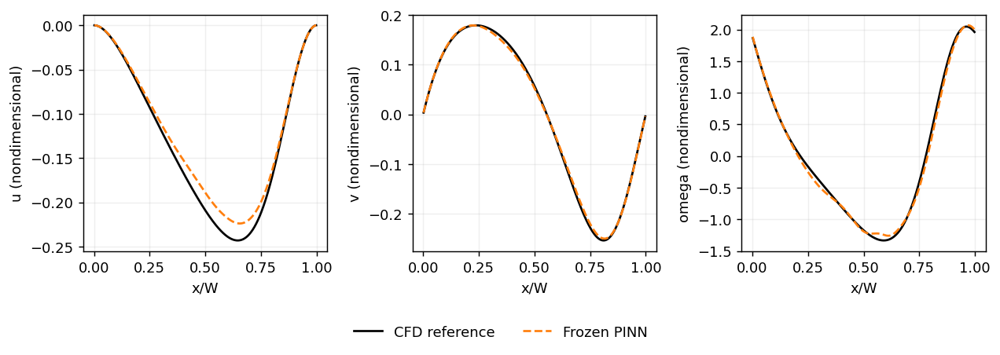

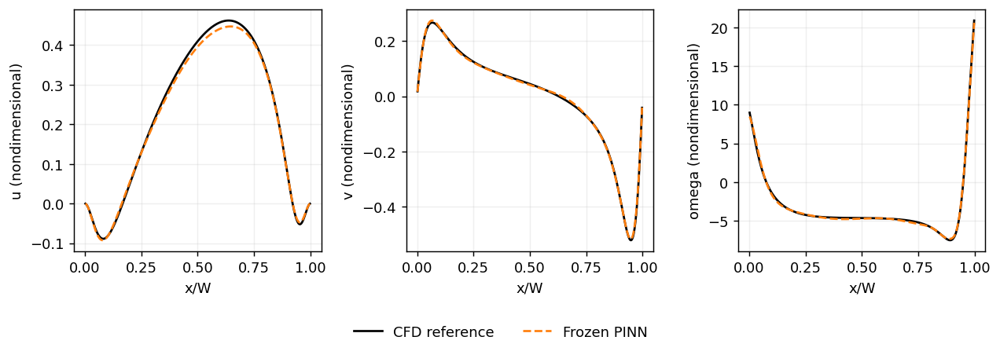

In [5]:
scored=[r for r in selected if r['outcome'] in ('scored','controlled_pilot_scored')]
for row in scored:
    print(row['run_id'],row['method'])
    if 'scores' in row and 'regions' in row['scores']:
        display(pd.DataFrame.from_dict(row['scores']['regions'],orient='index'))
    for audit_key in ['physics_audit','physical_residual_audit']:
        if audit_key in row: display(pd.json_normalize(row[audit_key]))
    show_native_profiles(row,[.1,.5,.9])
if not scored:
    print('No scored frozen fields for this selection; no accuracy conclusion is available.')

## Required student work

Submit these numbered artifacts; preserve failed runs and the frozen campaign.

1. **Table A — problem identity:** for Re100 and one high-Re case, record lid,
   coordinate units, collar, network, seed, sample count and audit roles. Flag any
   mismatch before comparing optimizers.
2. **Table B — sampling:** change the toy mixture to 0.1 and 0.5. Check the exact
   expected weighted objective and explain the change in the unweighted estimate.
   Explain why weight clipping is not a harmless numerical convenience.
3. **Figure 1/Table C — work:** overlay paired collars' recorded training RMS
   against closures and time. State that the last closure need not be the accepted
   endpoint. Compare final independent outer/shell audits separately. There is no
   independent audit history in this baseline, so do not invent one or use it to
   select a checkpoint. Optimizer variants require a separate controlled study.
4. **Figure 2/Table D — collar sensitivity:** compare 0.02W and 0.01W with matched
   starts and budget. Overlay signed physical profiles and report original residuals
   above, between and below the collars. Do changes exceed the method difference?
5. **Figure 3/Table E — physics:** for all available predeclared seeds, report
   interior and lower-quarter $A_R,e_R,E_R$, signed vorticity, and secondary-vortex
   locations. Compare with CFD grid sensitivity and report all failures.
6. **Table F — restart:** in a separately labeled small development run, interrupt
   Adam and L-BFGS once each. Compare next accepted update, parameters, predictions,
   counters and optimizer/sample/RNG states with an uninterrupted control.

Finish with one paragraph naming observable-specific wins/losses and remaining
uncertainty. Case-specific all-seven neural results already exist in literature;
this exercise demonstrates controlled comparison and reproducibility, not priority
or held-out-Re generalization.

In [6]:
display(pd.DataFrame(CAMPAIGN.get('collar_comparisons',[])))

,Re,seed,fine_run_id,coarse_run_id,fine_prediction_sha256,coarse_prediction_sha256,absolute_velocity_difference_rms_U,relative_velocity_difference,denominator,numeric_target_le_0_02,interpretation
0,100,7,re100_s7_eps0.01_2c826f7633,re100_s7_eps0.02_62d1c7ccc2,eac69b659240df31babb88523dc0324258585a3c692500...,b4b254a4d380efdc34ae31ecf4894c1a9c7c1eb4a1dc5a...,0.000000,0.000000,epsilon=0.01 PINN vector RMS on exactly matche...,True,paired collar sensitivity only; not full-domai...
1,100,23,re100_s23_eps0.01_74e2354a29,re100_s23_eps0.02_83805bfe22,9fe8362883774263224be97f5bc40fb36150dda660183e...,343c62e5276592a6ef0afe3a542bb1fb8c9d7a3a03294c...,0.007977,0.031504,epsilon=0.01 PINN vector RMS on exactly matche...,False,paired collar sensitivity only; not full-domai...
2,100,61,re100_s61_eps0.01_de2509420a,re100_s61_eps0.02_078ff8b31a,c49399834edeba07be5a2eee34cde72ce387d5b95e377f...,c49399834edeba07be5a2eee34cde72ce387d5b95e377f...,0.000000,0.000000,epsilon=0.01 PINN vector RMS on exactly matche...,True,paired collar sensitivity only; not full-domai...
3,400,7,re400_s7_eps0.01_62c49bac9c,re400_s7_eps0.02_e33f778ac0,5d623b9356044a683f03802359b7df004ec19c1eb4142b...,5d623b9356044a683f03802359b7df004ec19c1eb4142b...,0.000000,0.000000,epsilon=0.01 PINN vector RMS on exactly matche...,True,paired collar sensitivity only; not full-domai...
4,400,23,re400_s23_eps0.01_fcbe10e56c,re400_s23_eps0.02_69abc57ce6,3e2f2720e70783620e80119a1e455e2cefe8dc4c3f7e38...,6921cef50ee76ad7b1662505b21255b24c80b6cb575f68...,0.057040,0.344735,epsilon=0.01 PINN vector RMS on exactly matche...,False,paired collar sensitivity only; not full-domai...
5,400,61,re400_s61_eps0.01_85273f7176,re400_s61_eps0.02_d000a06523,74988e60b5fbb458da03b462dc09990dddf663e11ee94d...,74988e60b5fbb458da03b462dc09990dddf663e11ee94d...,0.000000,0.000000,epsilon=0.01 PINN vector RMS on exactly matche...,True,paired collar sensitivity only; not full-domai...
6,1000,7,re1000_s7_eps0.01_d43e72ce28,re1000_s7_eps0.02_46e52f2c19,4cb83ed5212c2e362eec5c2d718a0dd07840cf6ab72544...,4cb83ed5212c2e362eec5c2d718a0dd07840cf6ab72544...,0.000000,0.000000,epsilon=0.01 PINN vector RMS on exactly matche...,True,paired collar sensitivity only; not full-domai...
7,1000,23,re1000_s23_eps0.01_85d0daf350,re1000_s23_eps0.02_687ff66778,1b188e3521484a46267702b19a366473ea289b5b995d56...,c58bf3bd13684f0561f04c6af2dbc4cfdd529d2625faee...,0.046119,0.316852,epsilon=0.01 PINN vector RMS on exactly matche...,False,paired collar sensitivity only; not full-domai...
8,1000,61,re1000_s61_eps0.01_08b0c28dad,re1000_s61_eps0.02_7ddd97151b,0830225b7947e5dbf8d047bb0424d37710c01e58c77a31...,efcd81670175a35a48f3be24d852e692778fb3db42eb52...,0.020477,0.133364,epsilon=0.01 PINN vector RMS on exactly matche...,False,paired collar sensitivity only; not full-domai...
9,3200,7,re3200_s7_eps0.01_d1adbdafc6,re3200_s7_eps0.02_0c18c5111e,5ea9245465c5f2b314061fdb73857bc433f30e88e3f627...,5ea9245465c5f2b314061fdb73857bc433f30e88e3f627...,0.000000,0.000000,epsilon=0.01 PINN vector RMS on exactly matche...,True,paired collar sensitivity only; not full-domai...


## The completed fixed-budget baseline: retain the failures

The numerical ledger below reports every frozen endpoint. Successful execution is
not successful solution. Compare the signed flow profiles with the recorded loss:
a small training objective on a sparse fixed set can coexist with a poor interior
field and failed independent residual tests. This baseline uses one architecture
and one optimizer schedule; it does not establish that PINNs in general fail.

A zero difference between collars is informative only if their actual sample
sets differ. With sparse fixed random points, the removed annulus may contain
no collocation points at all. Inspect sample hashes and annulus coverage before
claiming collar robustness. This is separate from genuine outer/shell audits.

The existing accurate supervised POD-DeepONet learns CFD fields and remains a
separate experiment. It must not be used to describe this label-free baseline.

Physical acceptance: Not implied by the numeric counts; inspect all signed profiles and representative fields.
Re = 100 ; all three seeds and both collars
Re = 400 ; all three seeds and both collars
Re = 1000 ; all three seeds and both collars
Re = 3200 ; all three seeds and both collars
Re = 5000 ; all three seeds and both collars
Re = 7500 ; all three seeds and both collars
Re = 10000 ; all three seeds and both collars
Representative fields use predeclared seed 7, collar 0.02; no best-seed selection.


,scored_endpoints,non_scored_endpoints,numeric_pass_counts,all_four_numeric_targets,collar_pairs,collar_pairs_within_2_percent,physical_acceptance,sampling_coverage
0,42,0,"{'both_screened_ghia_relative_l2_le_0_02': 0, ...",0,21,13,Not implied by the numeric counts; inspect all...,"{'runs': 42, 'pairs': 21, 'identical_objective..."


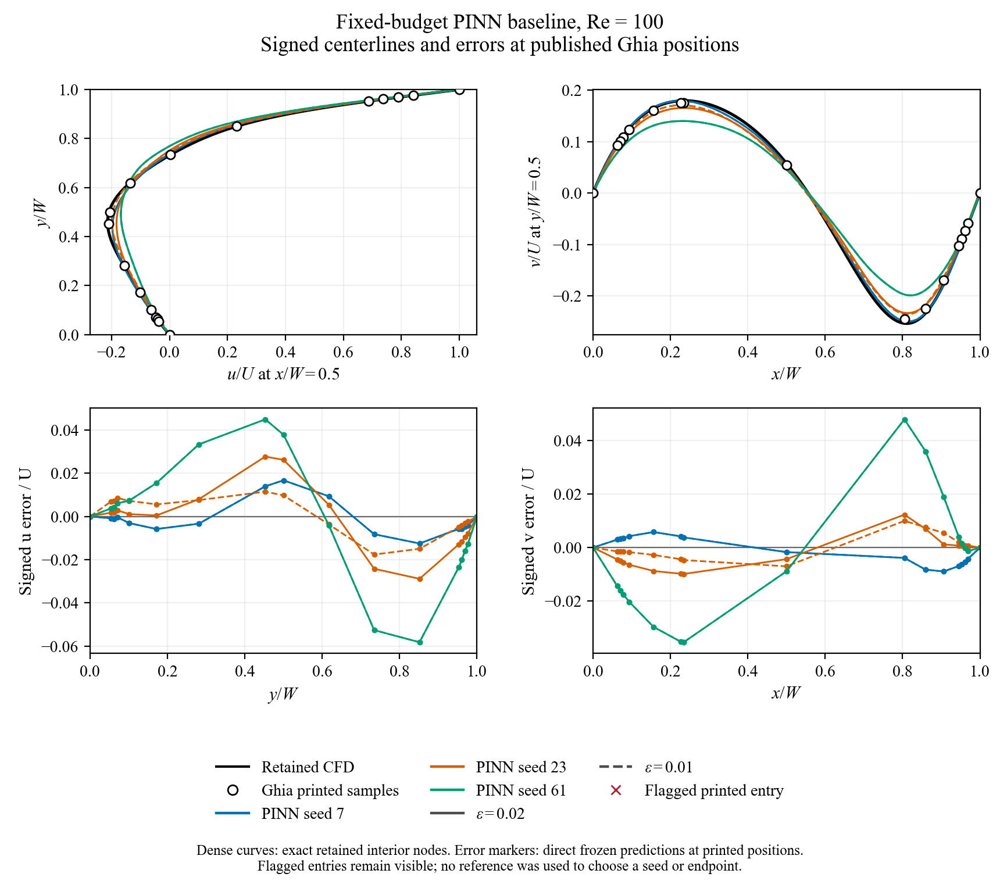

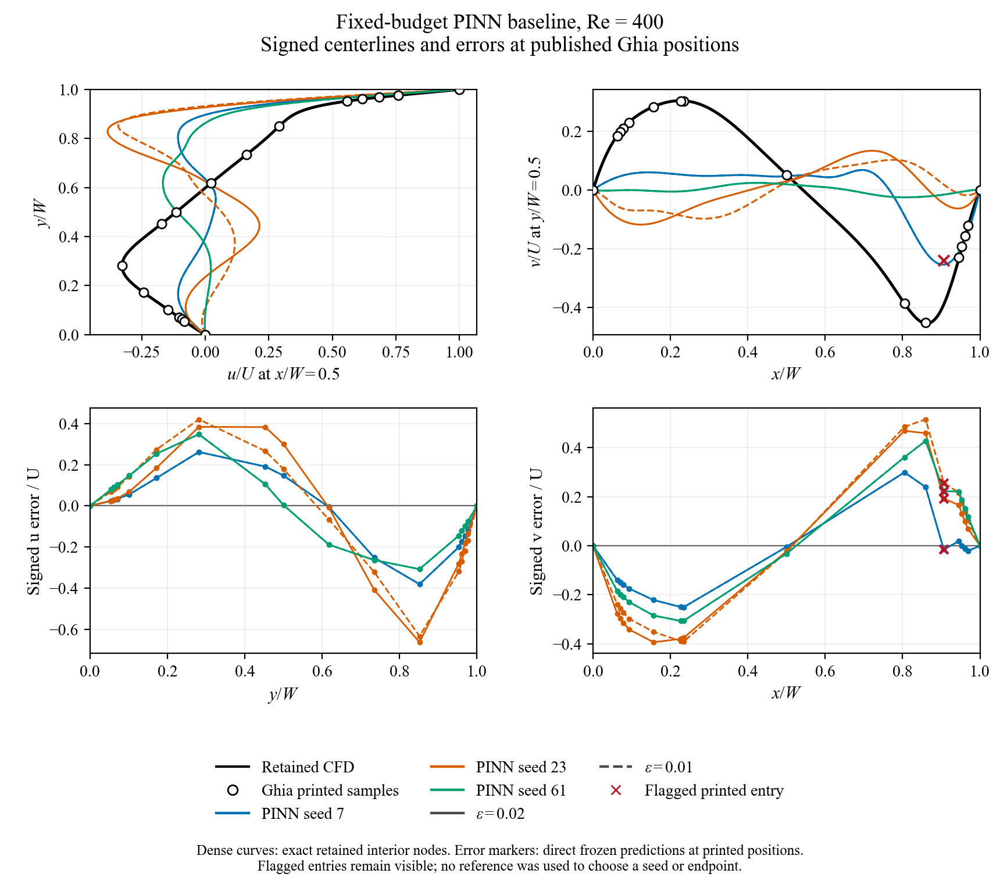

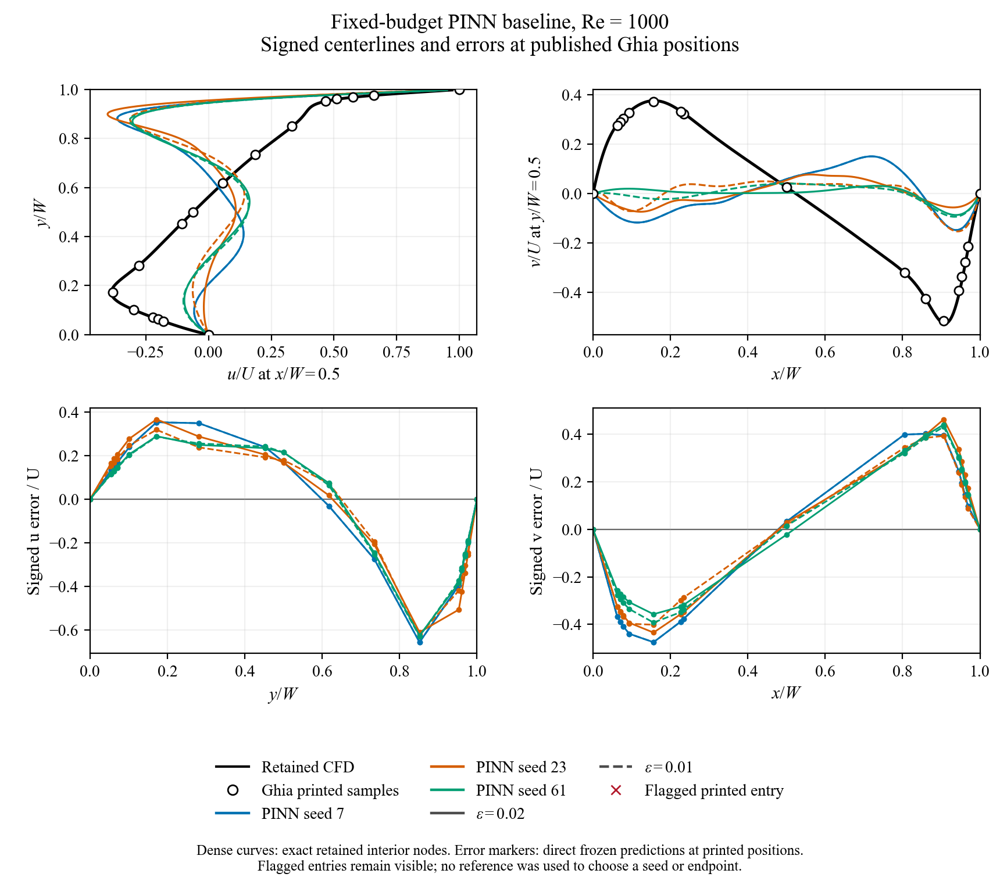

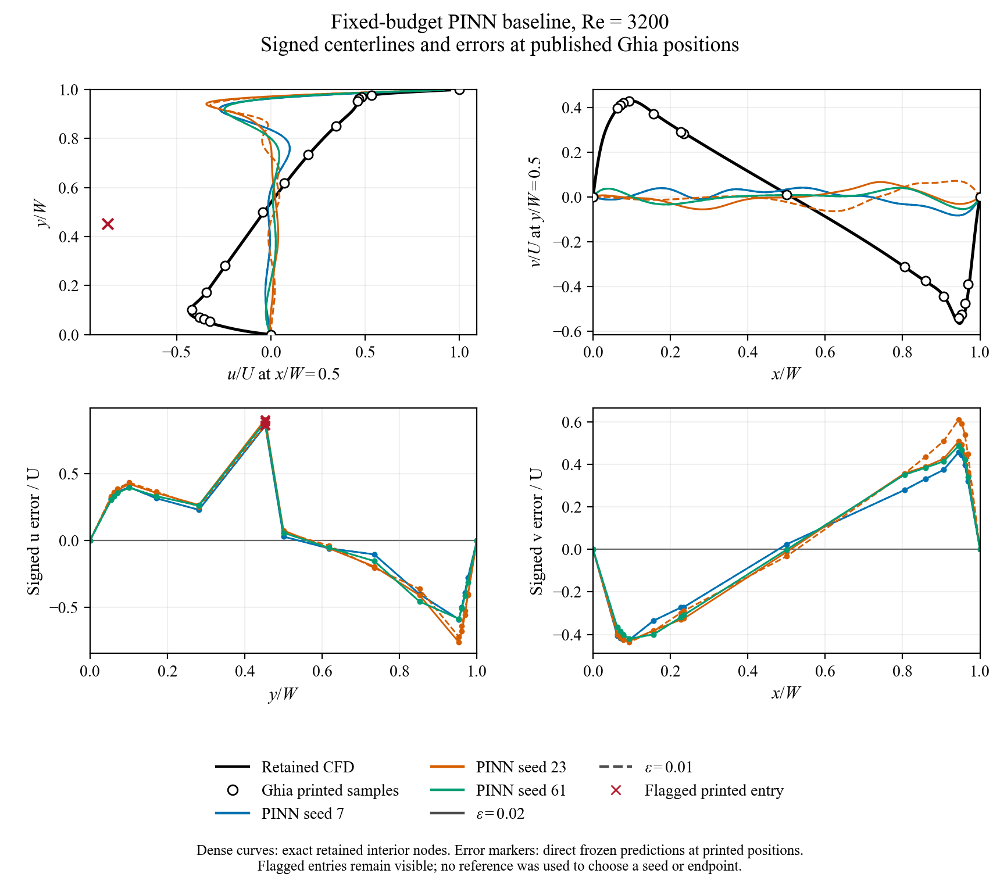

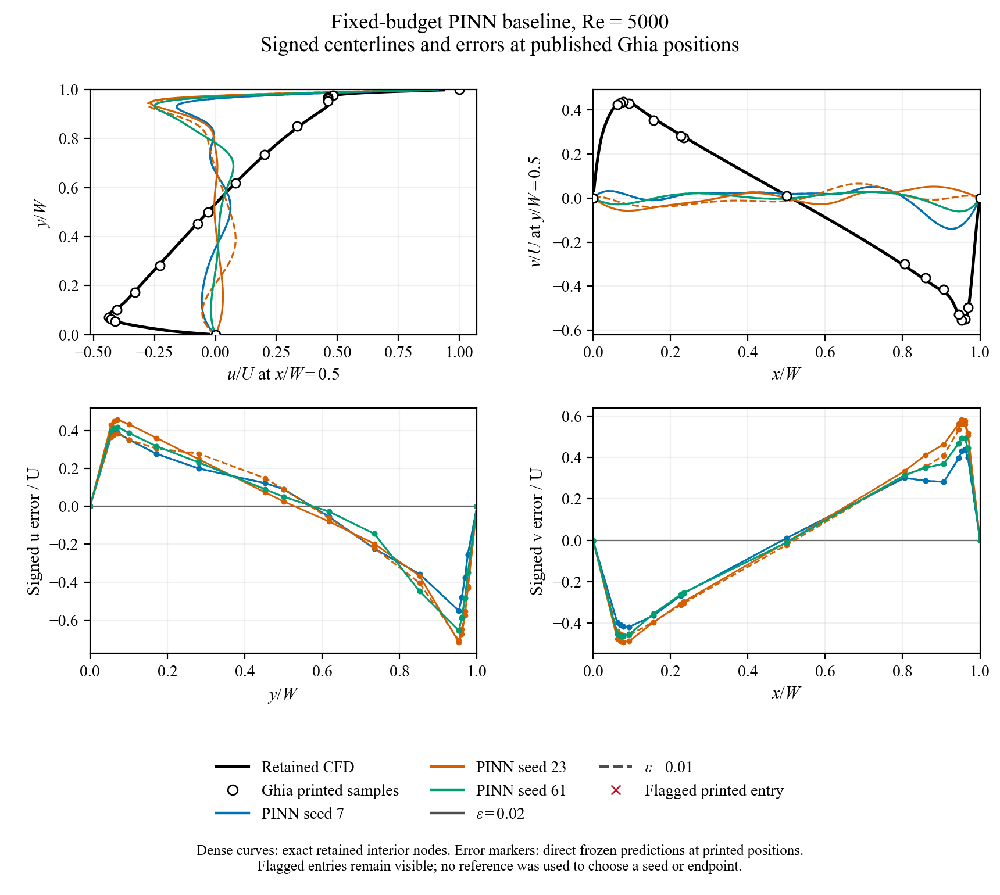

...

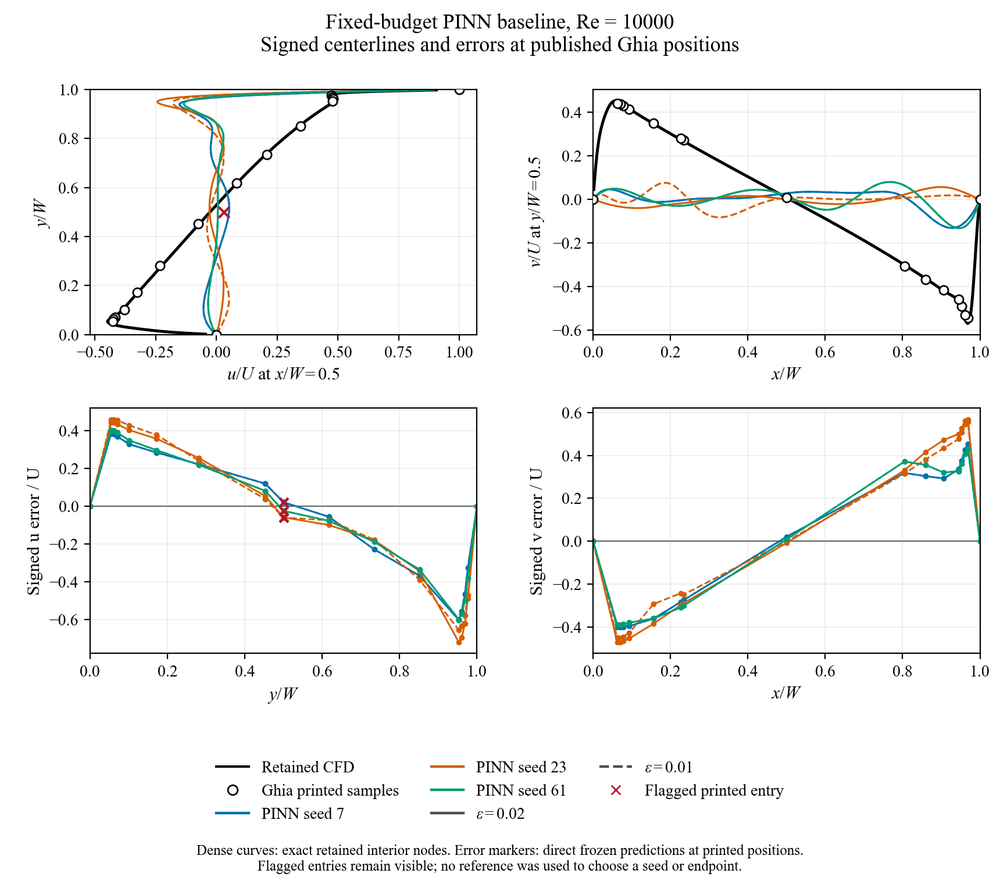

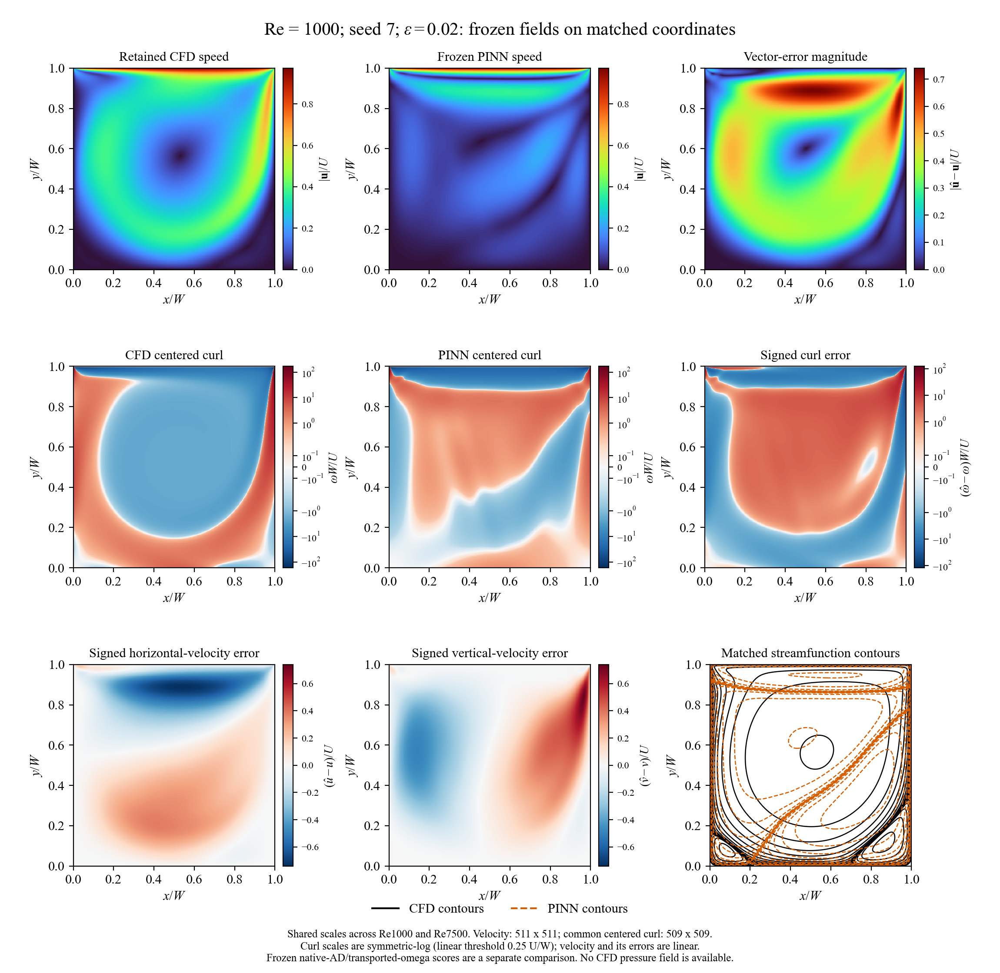

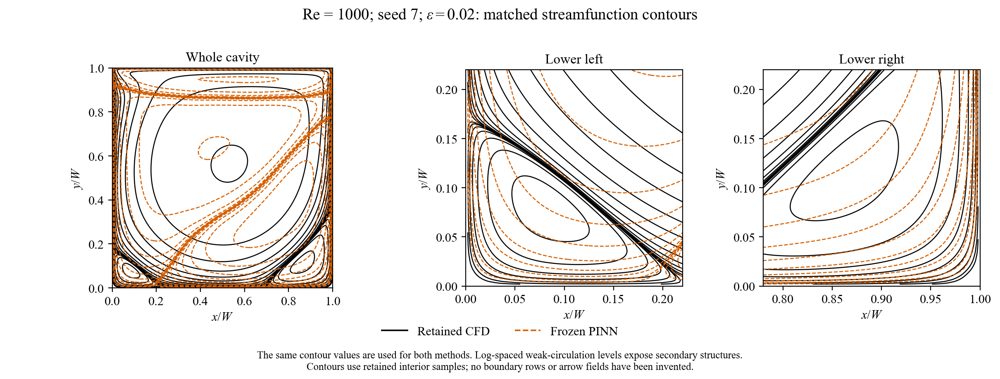

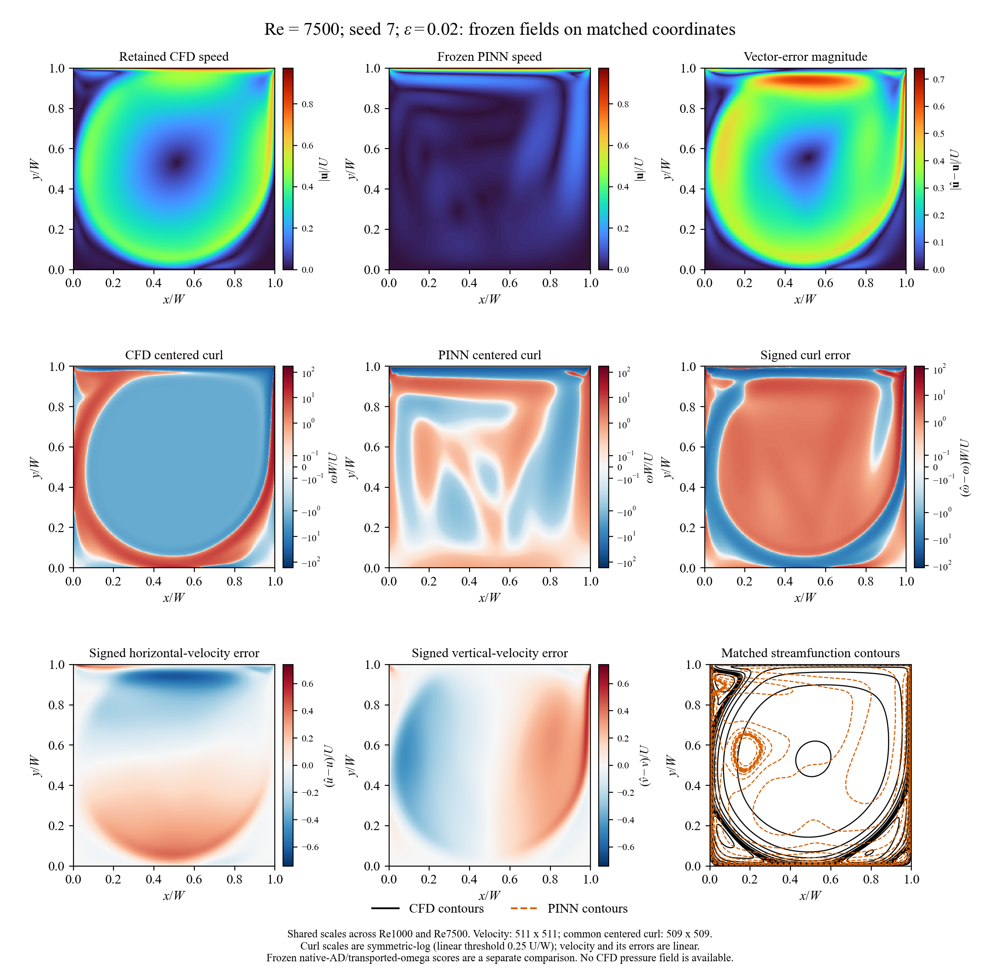

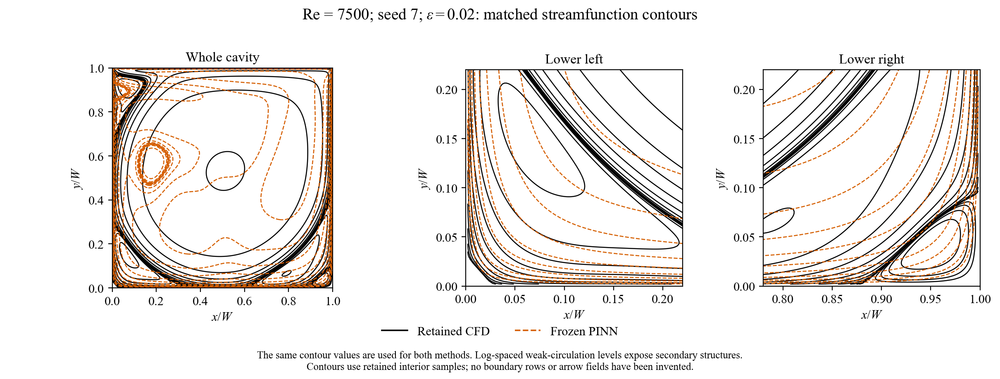

In [7]:
figure_manifest_path=ROOT/'results/cavity_pinn_campaign/figures/figure_manifest.json'
if figure_manifest_path.exists():
    figures=json.loads(figure_manifest_path.read_text(encoding='utf-8'))
    verified_file(figures['source_evaluation'])
    display(pd.DataFrame([figures['summary']]))
    print('Physical acceptance:',figures['summary']['physical_acceptance'])
    from IPython.display import Image
    for item in figures['figures']:
        if item.get('kind')=='signed_ghia_centerlines':
            print('Re =',item['Re'],'; all three seeds and both collars')
            display(Image(filename=str(verified_file(item)),width=1000))
    print('Representative fields use predeclared seed 7, collar 0.02; no best-seed selection.')
    for item in figures['figures']:
        if item.get('kind') in ('native_fields_and_derived_centered_curl','matched_streamfunction_contours'):
            display(Image(filename=str(verified_file(item)),width=1000))
else:
    print('The verified result gallery has not been generated yet. No placeholder curves are shown.')

## A bounded sampling intervention after the failed baseline

The follow-up changes only the fixed point distribution and its global area
weights at $Re=100,7500$, using seeds 7, 23, 61 and both collars. Each run has
exactly its own original baseline closure and residual-point work cap; those
caps can differ between collars or seeds. This is a newly declared development
experiment after the original failures, not retroactive validation of them.

The comparison preserves every paired outcome. It does not add CFD labels,
choose a best seed, smooth the constant lid or establish full-domain corner
integrability. Inspect signed profiles, near-wall fields and independent raw
residuals together. The original 42-run gallery above is unchanged.

**Saved samples are part of the scientific state.** Cross-host regeneration of
annular coordinates can differ in the last bits. The repaired inference path
loads the exact saved samples and complete trained state; it does not resample,
refit or certify cross-platform optimizer continuation. The ledger below reports
any earlier partial target access instead of presenting the repaired pass as
an evaluation that had never opened references.

**Required follow-up work:**
1. Produce **Table G** with every paired closure/point-work cap, initial-state hash,
   stratum count and weight sum. Explain which collar comparisons have unequal work.
2. Produce **Figure 4/Table H** with signed profiles and errors for all seeds at both
   Re. Find a case where an independent residual decreases while field error grows.
3. Produce **Figure 5/Table I** using seed 7, collar 0.02 and the shared field scales.
   Describe missing or displaced circulation and distinguish native vorticity scores
   from the extra common finite-difference curl.
4. Produce **Table J**, a chronology of the earlier scoring reads and exact-state
   evaluation repair. Explain what was preserved and what was not certified.

The earlier failed evaluation scored 4 cases and accessed targets. All 12 original trained endpoints had already frozen then. The repaired completed pass restores exact saved states, freezes all native projections before its own reference read, and performs no fitting or model selection.
signed_profiles_all_paired_seeds ; Re = 100 seed = all three
signed_profiles_all_paired_seeds ; Re = 100 seed = all three
signed_profiles_all_paired_seeds ; Re = 7500 seed = all three
signed_profiles_all_paired_seeds ; Re = 7500 seed = all three
matched_speed_fields ; Re = [100, 7500] seed = 7
matched_curl_fields ; Re = [100, 7500] seed = 7
signed_native_and_common_curl_errors ; Re = 100 seed = 7
three_method_streamfunction_overlay ; Re = 100 seed = 7
signed_native_and_common_curl_errors ; Re = 7500 seed = 7
three_method_streamfunction_overlay ; Re = 7500 seed = 7


,Re,seed,collar,metric,baseline,stratified,outcome
1,100,7,0.01,field.interior.velocity_relative_l2,0.033157,0.105626,worsened
8,100,7,0.01,field.lower_quarter.velocity_relative_l2,0.049630,0.169764,worsened
21,100,7,0.01,ghia.u.screened_relative_l2,0.016334,0.041384,worsened
25,100,7,0.01,ghia.v.screened_relative_l2,0.037020,0.146459,worsened
29,100,7,0.01,physics.outer_uniform.momentum_rms,0.171263,0.148920,diagnostic_only
38,100,7,0.02,field.interior.velocity_relative_l2,0.033157,0.104578,worsened
45,100,7,0.02,field.lower_quarter.velocity_relative_l2,0.049630,0.114744,worsened
58,100,7,0.02,ghia.u.screened_relative_l2,0.016334,0.047619,worsened
62,100,7,0.02,ghia.v.screened_relative_l2,0.037020,0.099318,worsened
66,100,7,0.02,physics.outer_uniform.momentum_rms,0.171263,0.110558,diagnostic_only


,Re,seed,collar,closure_cap,matched_residual_point_evaluations
0,100,7,0.01,3017,6178816
1,100,7,0.02,3017,6178816
2,100,23,0.01,3029,6203392
3,100,23,0.02,3011,6166528
4,100,61,0.01,3005,6154240
5,100,61,0.02,3005,6154240
6,7500,7,0.01,3023,6191104
7,7500,7,0.02,3023,6191104
8,7500,23,0.01,3049,6244352
9,7500,23,0.02,3015,6174720


,Re,seed,epsilon_0_01_closures,epsilon_0_02_closures,equal_work,convergence_claim,interpretation
0,100,7,3017,3017,True,False,equal total work; descriptive collar compariso...
1,100,23,3029,3011,False,False,unequal work across collars; cannot establish ...
2,100,61,3005,3005,True,False,equal total work; descriptive collar compariso...
3,7500,7,3023,3023,True,False,equal total work; descriptive collar compariso...
4,7500,23,3049,3015,False,False,unequal work across collars; cannot establish ...
5,7500,61,3008,3008,True,False,equal total work; descriptive collar compariso...


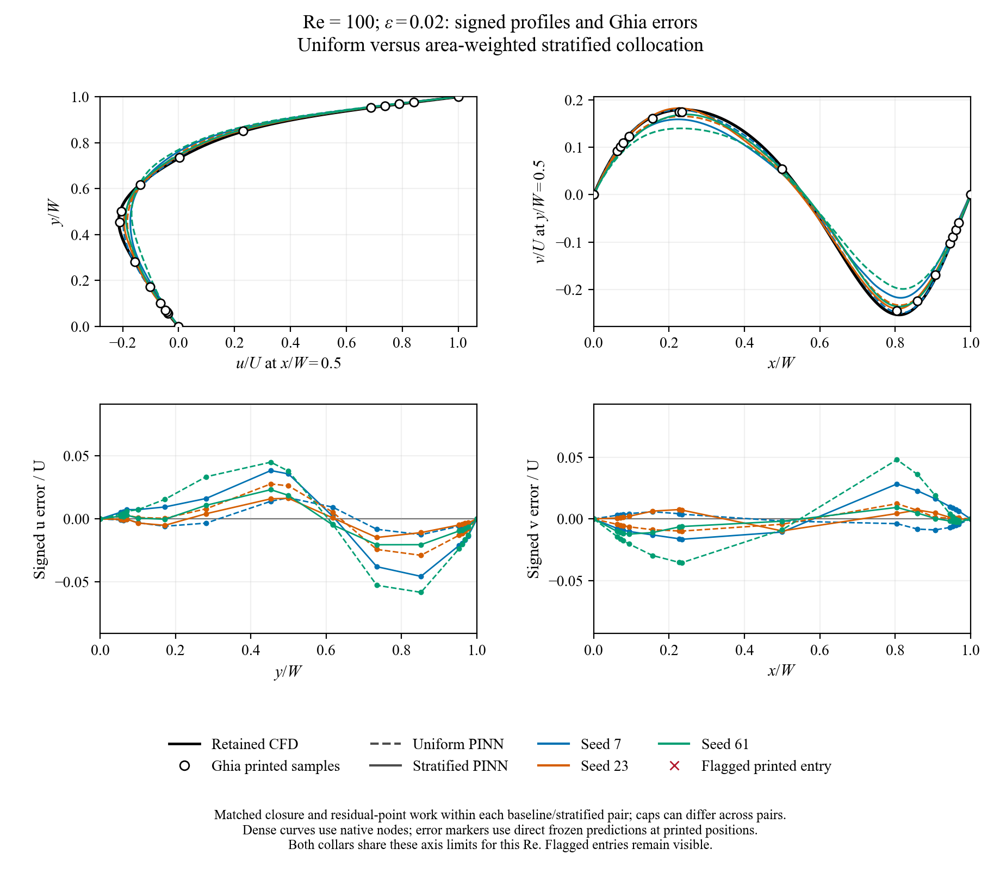

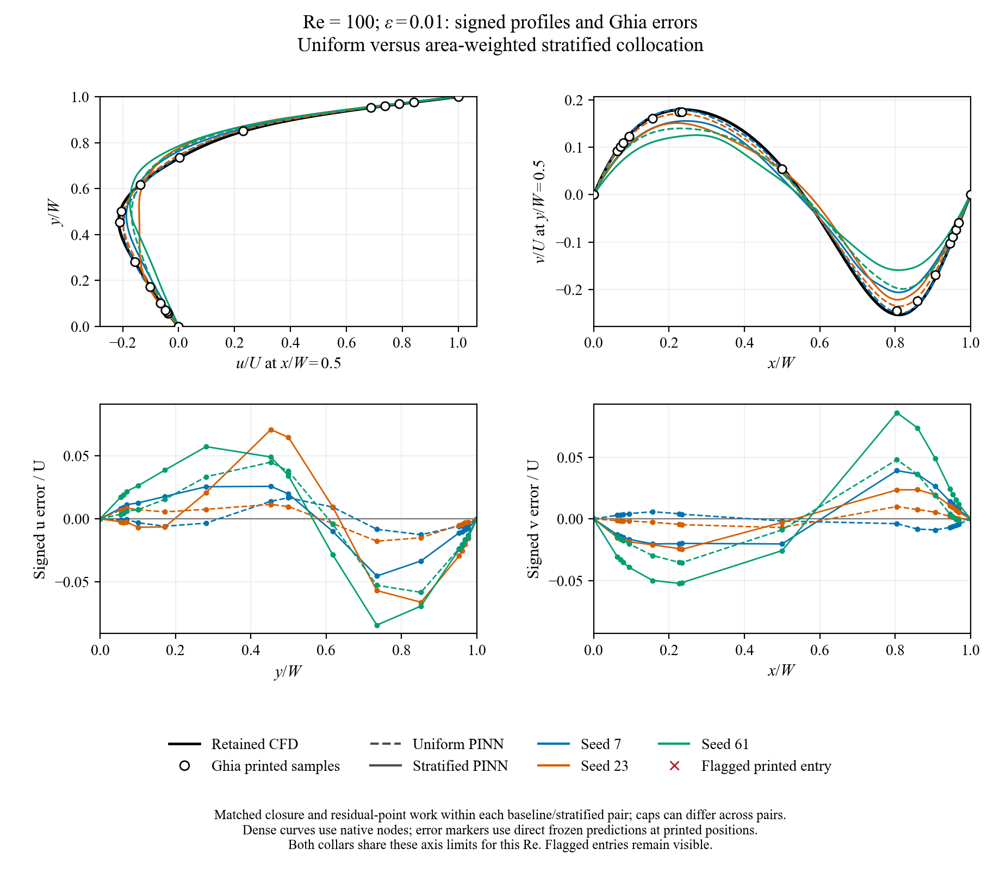

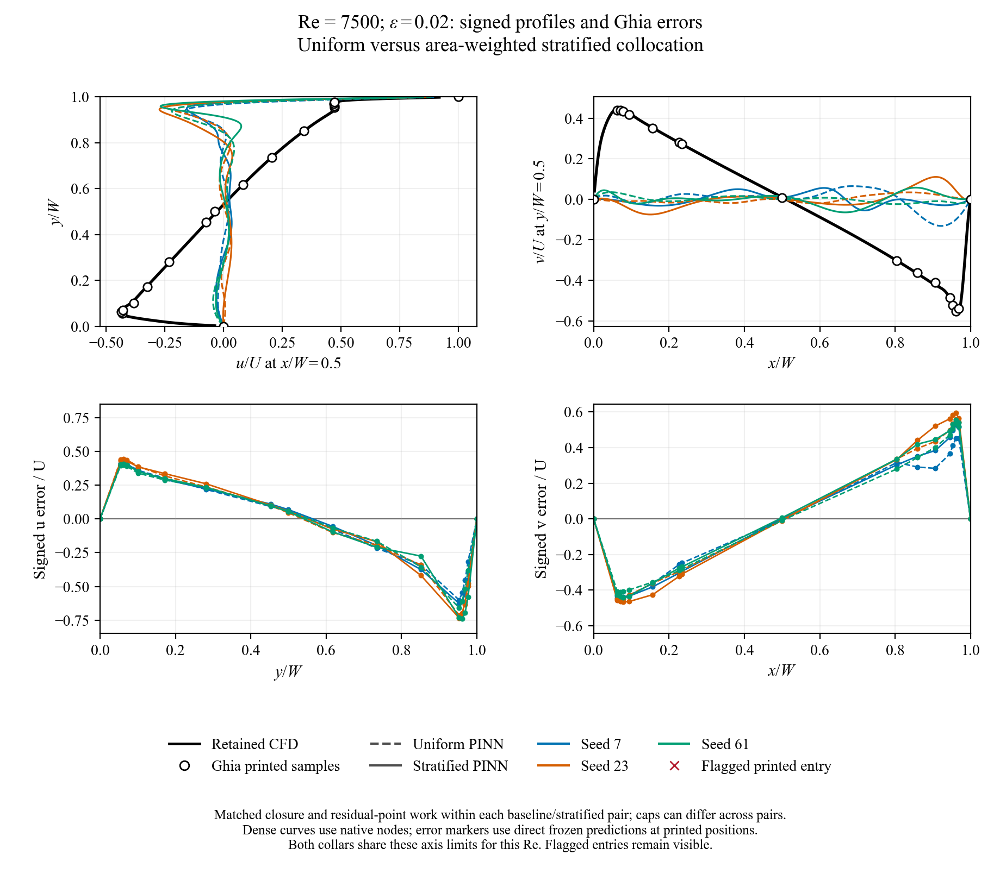

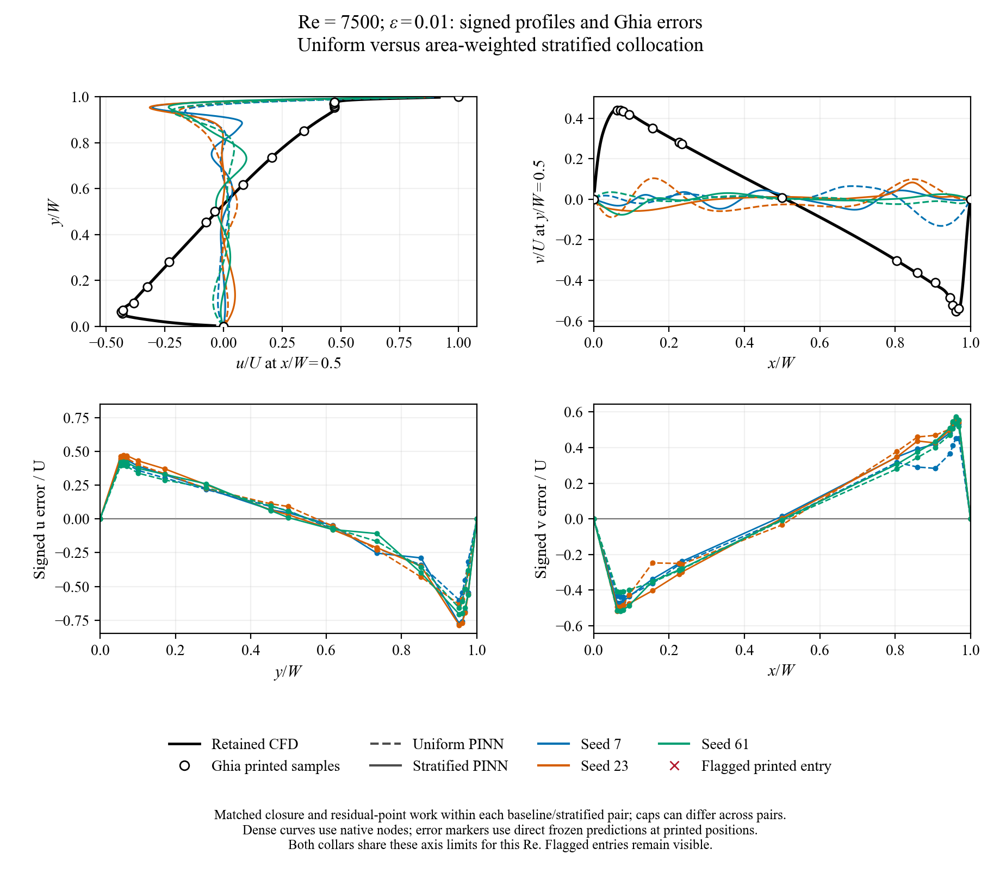

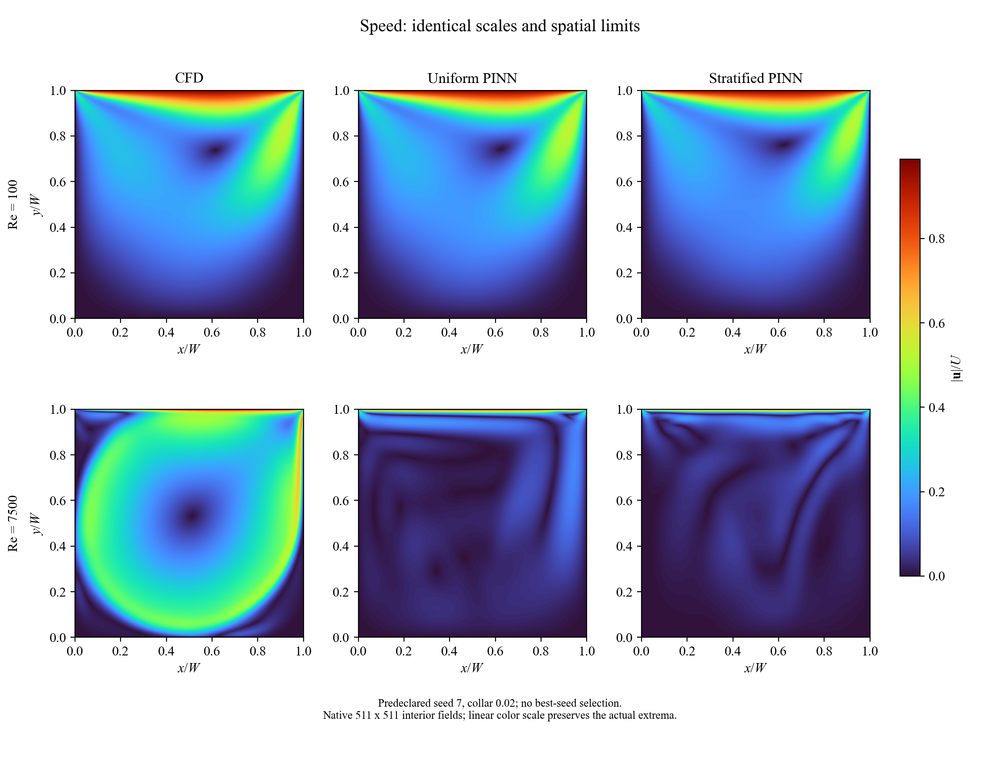

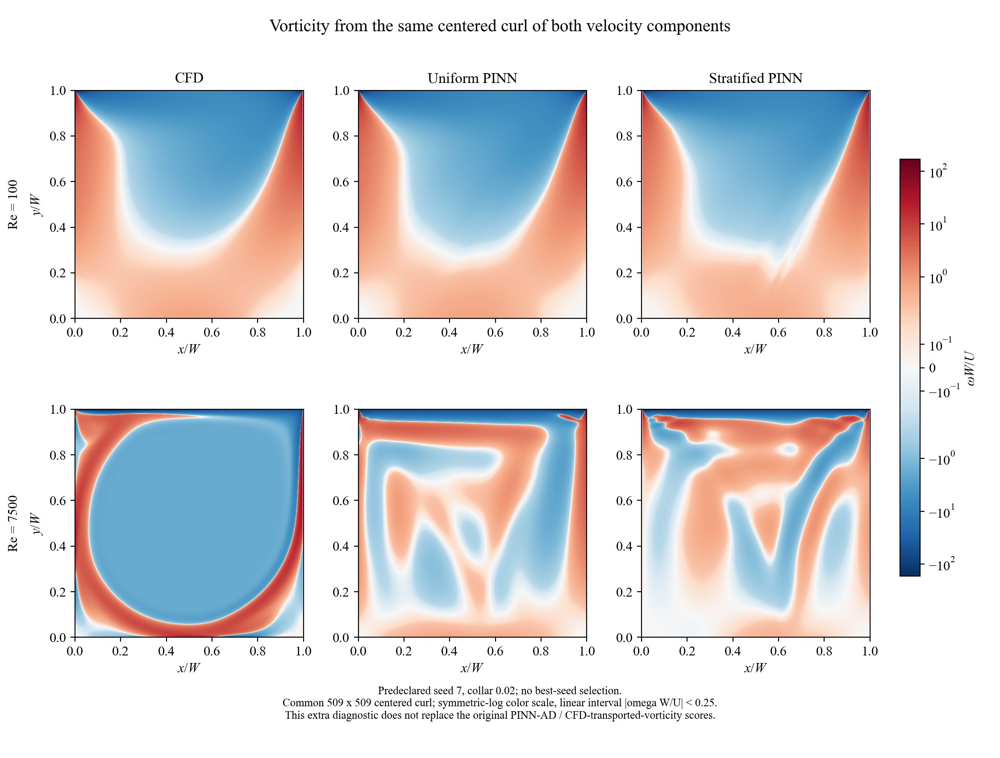

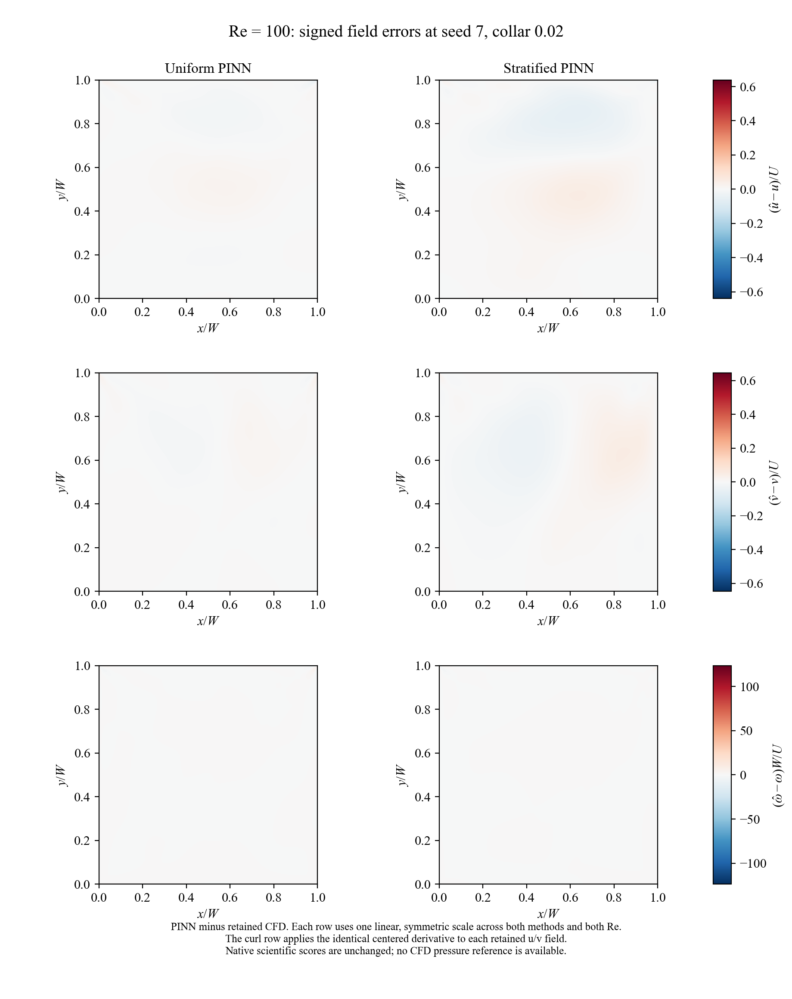

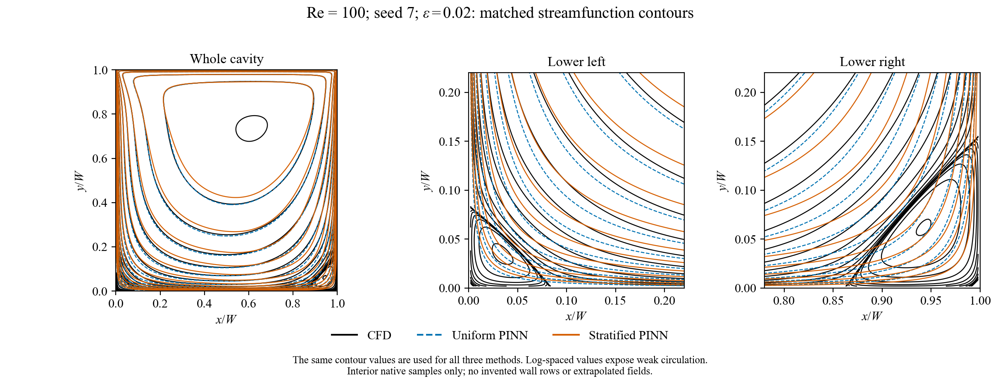

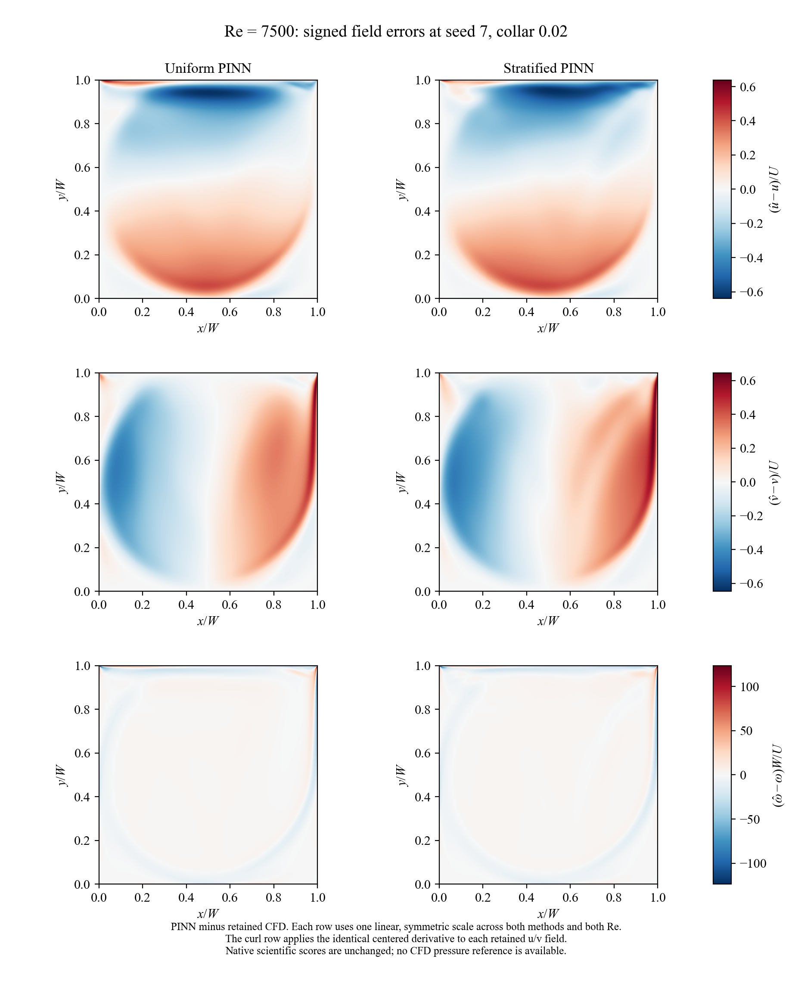

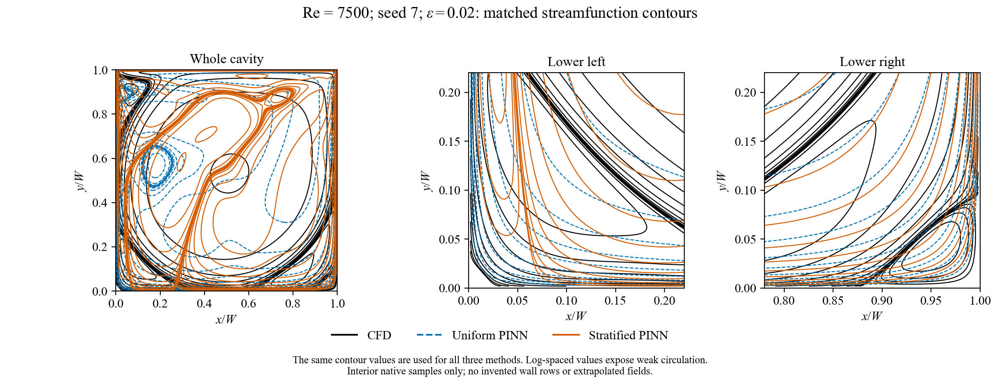

In [8]:
comparison_path=ROOT/'results/cavity_pinn_stratified/comparison/comparison_manifest.json'
if comparison_path.exists():
    STRATIFIED=json.loads(comparison_path.read_text(encoding='utf-8'))
    assert STRATIFIED['schema_version']==1 and STRATIFIED['campaign_kind']=='ghia_uniform_vs_stratified_matched_work'
    expected={(re,seed,epsilon) for re in [100,7500] for seed in [7,23,61] for epsilon in [.01,.02]}
    assert len(STRATIFIED['records'])==12
    assert {(r['Re'],r['seed'],r['collar']) for r in STRATIFIED['records']}==expected
    for item in STRATIFIED['inputs'].values(): verified_file(item)
    for item in STRATIFIED.get('evaluation_provenance',{}).values(): verified_file(item)
    print(STRATIFIED.get('evaluation_chronology',{}).get('disclosure','See the completed-pass provenance ledger.'))
    paired=pd.read_csv(verified_file(STRATIFIED['outputs']['paired_metrics']))
    metrics=['field.interior.velocity_relative_l2','field.lower_quarter.velocity_relative_l2',
             'ghia.u.screened_relative_l2','ghia.v.screened_relative_l2',
             'physics.outer_uniform.momentum_rms']
    display(paired[paired['metric'].isin(metrics)][['Re','seed','collar','metric','baseline','stratified','outcome']])
    display(pd.DataFrame(STRATIFIED['records'])[['Re','seed','collar','closure_cap','matched_residual_point_evaluations']])
    display(pd.DataFrame(STRATIFIED['collar_comparisons']))
    figure_path=ROOT/'results/cavity_pinn_stratified/figures/figure_manifest.json'
    if figure_path.exists():
        gallery=json.loads(figure_path.read_text(encoding='utf-8'))
        assert gallery['source_comparison']['sha256']==hashlib.sha256(comparison_path.read_bytes()).hexdigest()
        from IPython.display import Image
        for item in gallery['figures']:
            if item['path'].endswith('.png'):
                print(item['kind'],'; Re =',item.get('Re'),'seed =',item.get('seed','all three'))
                display(Image(filename=str(verified_file(item)),width=1000))
    else:
        print('Scored pairs exist, but the verified physical gallery is not available yet.')
else:
    print('The completed 12-pair sampling comparison is not available yet; no gain is inferred.')

## Post-freeze evidence interface

The parent scoring workflow writes `evaluation_manifest.json` separately from the
trainer. The notebook never launches training or silently downloads results.
The manifest has `schema_version: 1`, `campaign_kind`, `status`, and `records`.
Each record includes `run_id, Re, seed, method, outcome`; failed/unscored rows remain.
Ghia marks completed scores `scored`; D5 marks them `controlled_pilot_scored`.
The cost gate remains `cost_smoke_unscored` and cannot enter accuracy tables.
D5 exports may declare `path_base: manifest_directory`; those paths are resolved
inside the checkout. A cost-smoke row remains unscored and contains no reference
accuracy. A D5 `comparison_prediction` binds the original frozen prediction hash
and carries the declared common curl and already aligned global pressure gauge.
A scored row adds repository-relative `prediction`/`reference` file entries with
`path, sha256`, `freeze` with `prediction_sha256, at_utc`, and `score` with the same
`prediction_sha256` plus `reference_accessed_at_utc`. Optional `history` is a hashed
CSV containing `objective_evaluations, elapsed_seconds, metric_value` and `loss_location`.
Its file entry declares `metric_name`, `metric_label`, `independent_audit`, and cost scope.
The present Ghia history is `training_collar_momentum_rms`: the square root of the last
closure's training loss outside the collar, **not** an independent audit or a recomputed
accepted-endpoint residual. Only the fixed final model is scored. Its independent
outer/shell audits are separate final measurements, not a convergence history. Total residual-point
work includes adaptive candidate evaluation and audits; wall time must name its scope.

Native NPZs have increasing 1D `x,y` (or D5 `x,h`) and matching `(len(y),len(x))` arrays `u,v`;
optional `p,omega,psi` retain provenance. Here `y` is physical height above the floor
in units of width, not height normalized by cavity depth. Exact reference/prediction
coordinates are checked. Pressure comparisons use one whole-interior quadrature
mean shift; there is no separately fitted regional offset. A timestamp ledger records
ordering but cannot prove absence of unrecorded target access. Preserve source hashes,
trainer data-read records and independent review as well.

### Evidence and article-output contract

<!-- MIE690A article-aligned validation v3 -->
<!-- MIE690A additive course extension v1; prior lectures and notebooks remain unchanged -->

This is an additive teaching study, not a replacement for the manuscript's retained
figures or a claim that these fresh PINNs meet the paper's accuracy. Preserve the
separate evidence roles in [ARTICLE_FIGURE_MAP.md](../../ARTICLE_FIGURE_MAP.md).
Any later manuscript-facing figure must come from the frozen numerical outputs,
its documented generator and machine-readable metrics; do not redraw curves or
substitute a screenshot for a solver-to-reference comparison. A passed software
or provenance check is not passed scientific acceptance.

[Loss-landscape study](https://proceedings.mlr.press/v235/rathore24a.html) ·
[SOAP gradient-alignment study](https://arxiv.org/abs/2502.00604) ·
[Checked cavity literature](../../docs/CAVITY_ALL_RE_NEURAL_LITERATURE.md).
Published findings motivate experiments; they are not new local results.